variable quantitative "overallTime"

Étape 1 : Imports et chargement

In [6]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

df = pd.read_csv("results.csv")
print(df.shape)
df.head()

(1096719, 19)


,bib,Name,athleteLink,Country,Gender,Division,divLink,divisionRank,overallTime,overallRank,swimTime,swimRank,bikeTime,bikeRank,runTime,runRank,finishStatus,raceID,athleteID
0,40,Nils Frommhold,https://www.coachcox.co.uk/imstats/athlete/28963/,Germany,Male,MPRO,NaN,1.0,8:03:13,1.0,48:19,1.0,4:22:45,3.0,2:48:06,1.0,Finisher,1,28963.0
1,58,Paul Matthews,https://www.coachcox.co.uk/imstats/athlete/143...,United States,Male,MPRO,NaN,2.0,8:04:58,2.0,48:27,4.0,4:24:31,7.0,2:48:27,2.0,Finisher,1,143770.0
2,3,Tj Tollakson,https://www.coachcox.co.uk/imstats/athlete/33054/,United States,Male,MPRO,NaN,3.0,8:07:36,3.0,48:34,9.0,4:19:03,2.0,2:56:01,8.0,Finisher,1,33054.0
3,34,Tyler Butterfield,https://www.coachcox.co.uk/imstats/athlete/23792/,United States,Male,MPRO,NaN,4.0,8:14:41,4.0,52:28,22.0,4:26:02,10.0,2:52:02,4.0,Finisher,1,23792.0
4,41,Jarmo Hast,https://www.coachcox.co.uk/imstats/athlete/103...,Finland,Male,MPRO,NaN,5.0,8:16:09,5.0,51:36,17.0,4:32:03,16.0,2:48:36,3.0,Finisher,1,103580.0


In [7]:
df.info()
print(df.isna().sum())
print(df["overallTime"].head(10))
print(df["overallTime"].sample(10, random_state=1))

<class 'pandas.DataFrame'>
RangeIndex: 1096719 entries, 0 to 1096718
Data columns (total 19 columns):
 #   Column        Non-Null Count    Dtype  
---  ------        --------------    -----  
 0   bib           1096719 non-null  int64  
 1   Name          1096513 non-null  str    
 2   athleteLink   1020502 non-null  str    
 3   Country       1096717 non-null  str    
 4   Gender        1096453 non-null  str    
 5   Division      1096679 non-null  str    
 6   divLink       1069339 non-null  str    
 7   divisionRank  895696 non-null   float64
 8   overallTime   890912 non-null   str    
 9   overallRank   897773 non-null   float64
 10  swimTime      947570 non-null   str    
 11  swimRank      946708 non-null   float64
 12  bikeTime      935797 non-null   str    
 13  bikeRank      934974 non-null   float64
 14  runTime       889711 non-null   str    
 15  runRank       888912 non-null   float64
 16  finishStatus  1096719 non-null  str    
 17  raceID        1096719 non-null  int64 

2-Transformer les valeurs du format text comme "10:23:45" en minutes : 

In [11]:

df["overall_min"] = to_minutes(df["overallTime"])
df[["overallTime", "overall_min"]].head(10)


,overallTime,overall_min
0,8:03:13,483.216667
1,8:04:58,484.966667
2,8:07:36,487.600000
3,8:14:41,494.683333
4,8:16:09,496.150000
5,8:19:38,499.633333
6,8:20:36,500.600000
7,8:30:50,510.833333
8,8:35:08,515.133333
9,8:36:05,516.083333


In [13]:
x = df["overall_min"].dropna()
x

0           483.216667
1           484.966667
2           487.600000
3           494.683333
4           496.150000
              ...     
1096351    1001.800000
1096352    1010.433333
1096353    1012.233333
1096354    1014.016667
1096355    1030.833333
Name: overall_min, Length: 890912, dtype: float64

In [ ]:
Tendance centrale

In [15]:
print(f"Moyenne : {x.mean():.2f} min")
print(f"Médiane : {x.median():.2f} min")

Moyenne : 759.02 min
Médiane : 752.50 min


 Interprétation : 
La durée moyenne d’un Ironman est de 759,02 minutes (environ 12 h 39), tandis que la médiane est de 752,50 minutes (environ 12 h 32).
La moyenne est légèrement supérieure à la médiane (écart d’environ 6,5 minutes), ce qui indique que quelques athlètes avec des temps élevés tirent la moyenne vers le haut . 
La moitié des athlètes termine l’épreuve en moins de 12 h 32.

Indices de position

In [16]:
print(f"Min : {x.min():.2f} | Max : {x.max():.2f}")
q1, q2, q3 = x.quantile([0.25, 0.50, 0.75])
print(f"Q1 : {q1:.2f} | Q2 : {q2:.2f} | Q3 : {q3:.2f}")
x.describe()

Min : 368.97 | Max : 1413.00
Q1 : 675.50 | Q2 : 752.50 | Q3 : 838.25


count    890912.000000
mean        759.022228
std         111.551363
min         368.966667
25%         675.500000
50%         752.500000
75%         838.250000
max        1413.000000
Name: overall_min, dtype: float64

Indices de dispersion

In [18]:
print(f"Variance : {x.var():.2f}")
print(f"Écart-type : {x.std():.2f}")

Variance : 12443.71
Écart-type : 111.55


 Interprétation 
 L’écart-type (111,55 min) : un athlète finit environ 111 minutes (1 h 52) avant ou après la moyenne.
 Rapporté à la moyenne, cet écart représente environ 14,7 %, ce qui traduit une variabilité modérée autour de la moyenne .

Forme de la distribution

In [22]:
skew_pearson = 3 * (x.mean() - x.median()) / x.std()
print("Indice d'asymétrie (Pearson) :", skew_pearson, "\n")

Indice d'asymétrie (Pearson) : 0.1754051549719855 



Distribution quasi symétrique

 Valeurs aberrantes

In [23]:
iqr = q3 - q1
low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
n_out = ((x < low) | (x > high)).sum()
print(f"Bornes : [{low:.1f} ; {high:.1f}]")
print(f"Valeurs aberrantes : {n_out} ({100 * n_out / len(x):.2f} %)")

Bornes : [431.4 ; 1082.4]
Valeurs aberrantes : 83 (0.01 %)


Graphiques

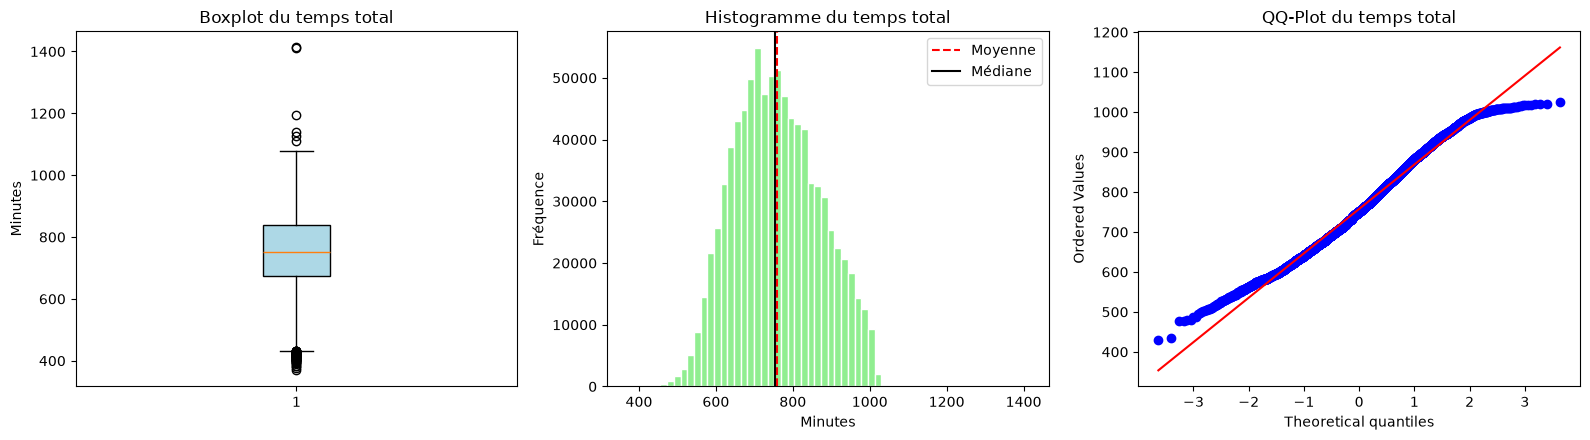

In [24]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

axes[0].boxplot(x, patch_artist=True, boxprops=dict(facecolor="lightblue"))
axes[0].set_title("Boxplot du temps total")
axes[0].set_ylabel("Minutes")

axes[1].hist(x, bins=60, color="lightgreen", edgecolor="white")
axes[1].axvline(x.mean(), color="red", ls="--", label="Moyenne")
axes[1].axvline(x.median(), color="black", label="Médiane")
axes[1].set_title("Histogramme du temps total")
axes[1].set_xlabel("Minutes")
axes[1].set_ylabel("Fréquence")
axes[1].legend()

sample = x.sample(min(5000, len(x)), random_state=42)
stats.probplot(sample, dist="norm", plot=axes[2])
axes[2].set_title("QQ-Plot du temps total")

plt.tight_layout()
plt.show()

Interprétation des Graphiques Univariés


       Boxplot (Boîte à moustaches) :
 La boîte, qui contient la moitié centrale des athlètes, s’étend environ de 680 à 850 minutes, avec la médiane (ligne orange) autour de 750 minutes, soit environ 12 h 30. La médiane est à peu près au centre de la boîte, ce qui indique une répartition équilibrée autour d’elle.
 Il y a des points isolés (outliers) aux deux extrémités : un groupe de temps très courts autour de 380 à 430 minutes, et quelques temps très longs, jusqu’à environ 1 400 minutes. Ces valeurs sont peu nombreuses par rapport à la taille du jeu de données.

  Histogramme (Distribution de fréquence) :
 L’histogramme montre une distribution unimodale (un seul pic), centrée autour de 700 à 750 minutes, avec une forme en cloche.
 La moyenne (ligne rouge) et la médiane (ligne noire) sont presque superposées, ce qui confirme une distribution quasi symétrique. La queue vers les temps élevés (800 à 1 000 minutes) est un peu plus étirée, ce qui correspond à une très légère asymétrie à droite, cohérente avec une moyenne légèrement supérieure à la médiane.
 Les outliers du boxplot (au-delà de 1 000 minutes) ne sont pas visibles sur l’histogramme, car ils sont trop rares.

  QQ-Plot (Quantile-Quantile Plot) :
 Les points suivent bien la droite rouge théorique dans la partie centrale, ce qui signifie que la majorité des temps se comporte comme une loi normale.
 Aux extrémités, les points s’écartent de la droite. À droite, ils se tassent autour de 1 000 à 1 030 minutes, au lieu de continuer à monter. C’est cohérent avec la limite de temps officielle d’un Ironman (17 heures, soit 1 020 minutes) : les athlètes ne peuvent pas finir bien au-delà.
 La variable est donc approximativement normale au centre, mais ne suit pas parfaitement une loi normale aux extrémités.